## novo projeto

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# localizando a pasta

base = Path.cwd()

if base.name == "notebooks":
    base = base.parent

data_dir = base / "data"

clientes = pd.read_csv(data_dir / "clientes.csv")
pedidos = pd.read_csv(data_dir / "pedidos.csv")
restaurantes = pd.read_csv(data_dir / "restaurantes.csv")
sessoes = pd.read_csv(data_dir / "sessoes.csv")

print("Clientes:", clientes.shape)
print("Pedidos:", pedidos.shape)
print("Restaurantes:", restaurantes.shape)
print("Sessões:", sessoes.shape)

display(pedidos.head())

Clientes: (3000, 5)
Pedidos: (17447, 7)
Restaurantes: (120, 5)
Sessões: (17447, 5)


,pedido_id,cliente_id,restaurante_id,sessao_id,criado_em,valor_bruto,moeda
0,P0000001,C000001,R0104,S0000001,2026-03-22T20:31:00+00:00,51.11,BRL
1,P0000002,C000001,R0081,S0000002,2026-01-28T19:12:00+00:00,27.36,BRL
2,P0000003,C000001,R0019,S0000003,2026-02-17T08:21:00+00:00,40.87,BRL
3,P0000004,C000001,R0116,S0000004,2026-01-31T14:05:00+00:00,36.84,BRL
4,P0000005,C000001,R0060,S0000005,2026-01-26T06:54:00+00:00,30.77,BRL


# conhecendo as variaveis

In [24]:
print("COLUNAS DE PEDIDOS")
print(pedidos.columns.tolist())

print("\nTIPOS DE DADOS")
print(pedidos.dtypes)

print("\nVALORES AUSENTES")
display(pedidos.isna().sum())

print("\nESTATÍSTICAS DESCRITIVAS")
display(pedidos.describe(include="all"))


COLUNAS DE PEDIDOS
['pedido_id', 'cliente_id', 'restaurante_id', 'sessao_id', 'criado_em', 'valor_bruto', 'moeda']

TIPOS DE DADOS
pedido_id          object
cliente_id         object
restaurante_id     object
sessao_id          object
criado_em          object
valor_bruto       float64
moeda              object
dtype: object

VALORES AUSENTES


pedido_id         0
cliente_id        0
restaurante_id    0
sessao_id         0
criado_em         0
valor_bruto       0
moeda             0
dtype: int64


ESTATÍSTICAS DESCRITIVAS


,pedido_id,cliente_id,restaurante_id,sessao_id,criado_em,valor_bruto,moeda
count,17447,17447,17447,17447,17447,17447.000000,17447
unique,17447,2665,120,17447,15832,NaN,1
top,P0000001,C001549,R0060,S0000001,2026-01-14T17:53:00+00:00,NaN,BRL
freq,1,93,706,1,4,NaN,17447
mean,NaN,NaN,NaN,NaN,NaN,52.681288,NaN
std,NaN,NaN,NaN,NaN,NaN,24.926692,NaN
min,NaN,NaN,NaN,NaN,NaN,9.720000,NaN
25%,NaN,NaN,NaN,NaN,NaN,34.340000,NaN
50%,NaN,NaN,NaN,NaN,NaN,47.490000,NaN
75%,NaN,NaN,NaN,NaN,NaN,65.650000,NaN


# frequencia de pedidos por clientes

count    2665.000000
mean        6.546717
std         7.159761
min         1.000000
25%         2.000000
50%         4.000000
75%         8.000000
max        93.000000
dtype: float64

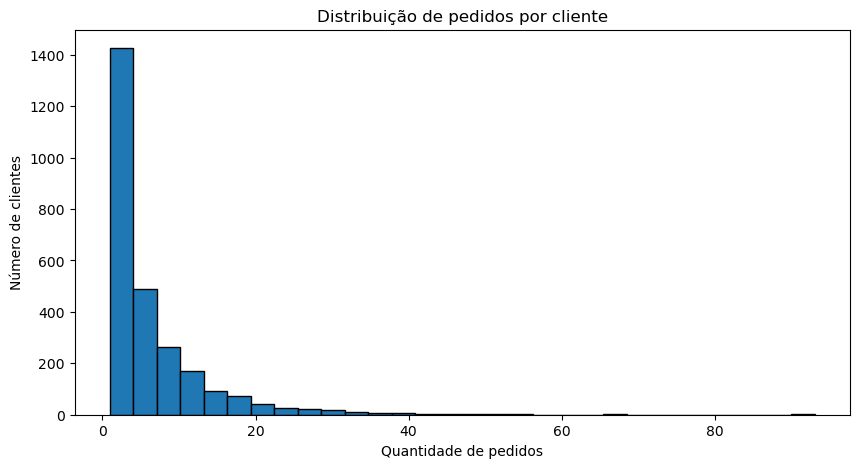

In [25]:
frequencia = pedidos.groupby("cliente_id").size()

display(frequencia.describe())

plt.figure(figsize=(10, 5))

plt.hist(
    frequencia,
    bins=30,
    edgecolor="black"
)

plt.title("Distribuição de pedidos por cliente")
plt.xlabel("Quantidade de pedidos")
plt.ylabel("Número de clientes")

plt.show()

# incluindo os clientes sem pedidos

In [26]:
# Frequência considerando todas as contas
frequencia_total = (
    clientes[["cliente_id"]]
    .merge(
        pedidos.groupby("cliente_id")
        .size()
        .rename("qtd_pedidos"),
        on="cliente_id",
        how="left"
    )
)

frequencia_total["qtd_pedidos"] = (
    frequencia_total["qtd_pedidos"]
    .fillna(0)
    .astype(int)
)

display(frequencia_total["qtd_pedidos"].describe())

print(
    "Variância:",
    frequencia_total["qtd_pedidos"].var()
)

print(
    "Índice de dispersão:",
    frequencia_total["qtd_pedidos"].var()
    / frequencia_total["qtd_pedidos"].mean()
)

count    3000.000000
mean        5.815667
std         7.056129
min         0.000000
25%         1.000000
50%         3.000000
75%         7.000000
max        93.000000
Name: qtd_pedidos, dtype: float64

Variância: 49.788950872513155
Índice de dispersão: 8.561176856625176


# primeiro grafico analitico masi aprofundado

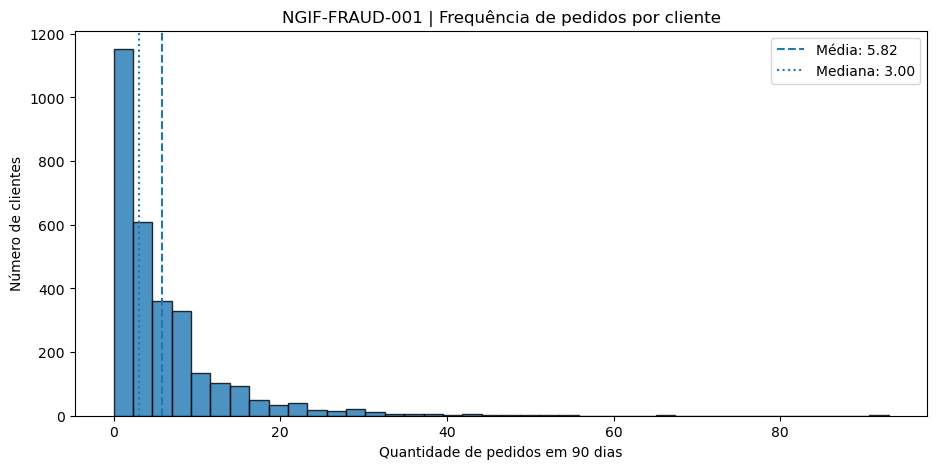

In [27]:
import matplotlib.pyplot as plt

freq = frequencia_total["qtd_pedidos"]

plt.figure(figsize=(11, 5))

plt.hist(
    freq,
    bins=40,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    freq.mean(),
    linestyle="--",
    label=f"Média: {freq.mean():.2f}"
)

plt.axvline(
    freq.median(),
    linestyle=":",
    label=f"Mediana: {freq.median():.2f}"
)

plt.title("NGIF-FRAUD-001 | Frequência de pedidos por cliente")
plt.xlabel("Quantidade de pedidos em 90 dias")
plt.ylabel("Número de clientes")
plt.legend()
plt.show()

# valores monetarios dos pedidos

In [28]:
print(pedidos.columns.tolist())
display(pedidos.head(5))

['pedido_id', 'cliente_id', 'restaurante_id', 'sessao_id', 'criado_em', 'valor_bruto', 'moeda']


,pedido_id,cliente_id,restaurante_id,sessao_id,criado_em,valor_bruto,moeda
0,P0000001,C000001,R0104,S0000001,2026-03-22T20:31:00+00:00,51.11,BRL
1,P0000002,C000001,R0081,S0000002,2026-01-28T19:12:00+00:00,27.36,BRL
2,P0000003,C000001,R0019,S0000003,2026-02-17T08:21:00+00:00,40.87,BRL
3,P0000004,C000001,R0116,S0000004,2026-01-31T14:05:00+00:00,36.84,BRL
4,P0000005,C000001,R0060,S0000005,2026-01-26T06:54:00+00:00,30.77,BRL


## primeiro experimento - distribuicao de valores

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Garantir que os valores sejam numéricos
pedidos["valor_bruto"] = pd.to_numeric(
    pedidos["valor_bruto"],
    errors="coerce"
)

print("ESTATÍSTICAS DOS VALORES DOS PEDIDOS")

display(
    pedidos["valor_bruto"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nAssimetria:",
      pedidos["valor_bruto"].skew())

print("\nValores ausentes:",
      pedidos["valor_bruto"].isna().sum())

print("\nMoedas registradas:")
display(pedidos["moeda"].value_counts())

ESTATÍSTICAS DOS VALORES DOS PEDIDOS


count    17447.000000
mean        52.681288
std         24.926692
min          9.720000
25%         34.340000
50%         47.490000
75%         65.650000
90%         86.504000
95%        100.761000
99%        132.347000
max        234.480000
Name: valor_bruto, dtype: float64


Assimetria: 1.2057722069852945

Valores ausentes: 0

Moedas registradas:


moeda
BRL    17447
Name: count, dtype: int64

# segundo experimento - histograma

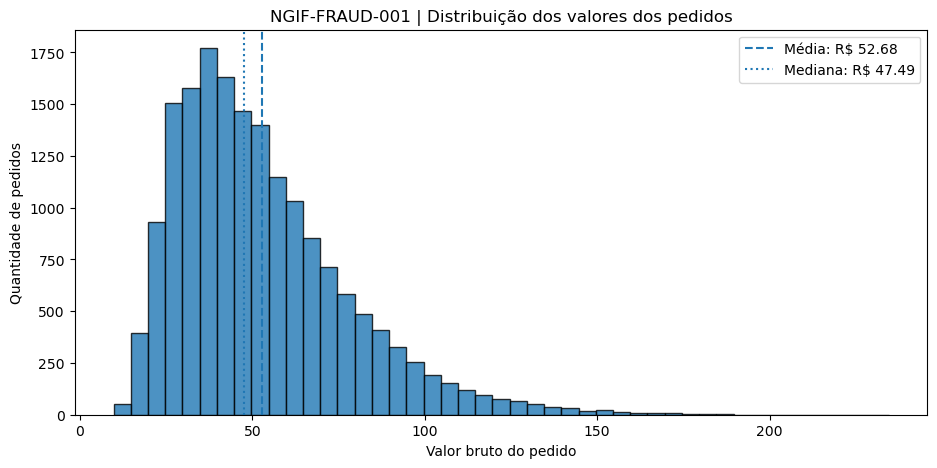

In [30]:
valores = pedidos["valor_bruto"].dropna()

plt.figure(figsize=(11, 5))

plt.hist(
    valores,
    bins=45,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    valores.mean(),
    linestyle="--",
    label=f"Média: R$ {valores.mean():.2f}"
)

plt.axvline(
    valores.median(),
    linestyle=":",
    label=f"Mediana: R$ {valores.median():.2f}"
)

plt.title("NGIF-FRAUD-001 | Distribuição dos valores dos pedidos")
plt.xlabel("Valor bruto do pedido")
plt.ylabel("Quantidade de pedidos")
plt.legend()
plt.show()

# terceiro experimento - concentração financeira por restaurantes

In [31]:
analise_restaurantes = (
    pedidos.groupby("restaurante_id")
    .agg(
        total_pedidos=("pedido_id", "count"),
        faturamento_bruto=("valor_bruto", "sum"),
        ticket_medio=("valor_bruto", "mean"),
        clientes_unicos=("cliente_id", "nunique")
    )
    .sort_values("faturamento_bruto", ascending=False)
)

display(analise_restaurantes.head(10))

,total_pedidos,faturamento_bruto,ticket_medio,clientes_unicos
restaurante_id,,,,
R0022,661,50557.50,76.486384,394
R0020,501,38709.69,77.264850,328
R0060,706,32507.08,46.044023,406
R0074,411,31023.03,75.481825,257
R0114,383,30439.38,79.476188,262
R0067,348,26003.39,74.722385,248
R0087,414,19440.04,46.956618,280
R0011,242,19345.12,79.938512,188
R0097,281,18664.03,66.420036,217


In [32]:
# Faturamento bruto total do marketplace
faturamento_total = pedidos["valor_bruto"].sum()

# Faturamento dos 10 maiores restaurantes
top10 = analise_restaurantes.head(10)

faturamento_top10 = top10["faturamento_bruto"].sum()

participacao_top10 = (
    faturamento_top10 / faturamento_total
) * 100

print(f"Faturamento total: R$ {faturamento_total:,.2f}")
print(f"Faturamento Top 10: R$ {faturamento_top10:,.2f}")
print(f"Participação Top 10: {participacao_top10:.2f}%")

Faturamento total: R$ 919,130.44
Faturamento Top 10: R$ 284,947.20
Participação Top 10: 31.00%


In [33]:
dispositivos = pd.read_csv(data_dir / "dispositivos.csv")

print("COLUNAS DE DISPOSITIVOS")
print(dispositivos.columns.tolist())

print("\nCOLUNAS DE SESSÕES")
print(sessoes.columns.tolist())

display(dispositivos.head())
display(sessoes.head())

COLUNAS DE DISPOSITIVOS
['device_id', 'device_type']

COLUNAS DE SESSÕES
['sessao_id', 'cliente_id', 'device_id', 'ip_token', 'iniciada_em']


,device_id,device_type
0,D000001,ios
1,D000002,ios
2,D000003,ios
3,D000004,ios
4,D000005,android


,sessao_id,cliente_id,device_id,ip_token,iniciada_em
0,S0000001,C000001,D000001,IP00101,2026-03-22T20:31:00+00:00
1,S0000002,C000001,D000001,IP00101,2026-01-28T19:12:00+00:00
2,S0000003,C000001,D000001,IP00101,2026-02-17T08:21:00+00:00
3,S0000004,C000001,D000001,IP00101,2026-01-31T14:05:00+00:00
4,S0000005,C000001,D000001,IP00006,2026-01-26T06:54:00+00:00


# primeira analise relacional - contas por dispositivos

In [34]:
contas_por_dispositivo = (
    sessoes.groupby("device_id")["cliente_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("ESTATÍSTICAS DE COMPARTILHAMENTO")
display(contas_por_dispositivo.describe())

print("\nTOP 10 DISPOSITIVOS MAIS COMPARTILHADOS")
display(contas_por_dispositivo.head(10))

print("\nDISPOSITIVOS UTILIZADOS POR MAIS DE UMA CONTA")
print((contas_por_dispositivo > 1).sum())

ESTATÍSTICAS DE COMPARTILHAMENTO


count    1599.000000
mean        1.666667
std         0.823366
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         4.000000
Name: cliente_id, dtype: float64


TOP 10 DISPOSITIVOS MAIS COMPARTILHADOS


device_id
D001479    4
D001238    4
D001368    4
D001626    4
D001583    4
D001023    4
D001181    4
D000975    4
D001027    4
D000265    4
Name: cliente_id, dtype: int64


DISPOSITIVOS UTILIZADOS POR MAIS DE UMA CONTA
753


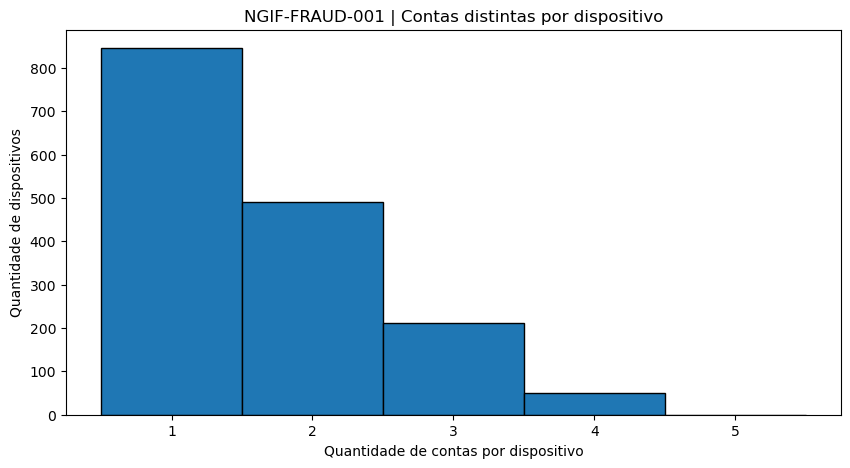

In [35]:
plt.figure(figsize=(10, 5))

plt.hist(
    contas_por_dispositivo,
    bins=range(
        1,
        int(contas_por_dispositivo.max()) + 3
    ),
    align="left",
    edgecolor="black"
)

plt.title(
    "NGIF-FRAUD-001 | Contas distintas por dispositivo"
)
plt.xlabel("Quantidade de contas por dispositivo")
plt.ylabel("Quantidade de dispositivos")

plt.xticks(
    range(1, int(contas_por_dispositivo.max()) + 2)
)

plt.show()

In [36]:
# Relações únicas entre clientes e dispositivos
cliente_dispositivo = (
    sessoes[["cliente_id", "device_id"]]
    .drop_duplicates()
)

# Número de contas por dispositivo
qtd_contas = (
    cliente_dispositivo.groupby("device_id")["cliente_id"]
    .nunique()
    .rename("contas_no_dispositivo")
)

# Associar a contagem às relações
cliente_dispositivo = cliente_dispositivo.merge(
    qtd_contas,
    on="device_id",
    how="left"
)

# Feature por cliente
features_dispositivo = (
    cliente_dispositivo.groupby("cliente_id")
    .agg(
        max_contas_dispositivo=(
            "contas_no_dispositivo", "max"
        ),
        dispositivos_distintos=("device_id", "nunique")
    )
    .reset_index()
)

display(features_dispositivo.head(10))

,cliente_id,max_contas_dispositivo,dispositivos_distintos
0,C000001,2,1
1,C000002,2,1
2,C000003,2,1
3,C000004,2,1
4,C000005,3,1
5,C000006,3,1
6,C000007,3,1
7,C000009,2,1
8,C000010,2,1
9,C000013,1,1


# investigando os IPs

In [37]:
contas_por_ip = (
    sessoes.groupby("ip_token")["cliente_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("ESTATÍSTICAS DE CONTAS POR IP")
display(contas_por_ip.describe())

print("\nTOP 10 IPs MAIS COMPARTILHADOS")
display(contas_por_ip.head(10))

print("\nIPs COM MAIS DE UMA CONTA")
print((contas_por_ip > 1).sum())

ESTATÍSTICAS DE CONTAS POR IP


count    1632.000000
mean        3.087010
std         7.949937
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        67.000000
Name: cliente_id, dtype: float64


TOP 10 IPs MAIS COMPARTILHADOS


ip_token
IP00012    67
IP00011    63
IP00035    59
IP00018    58
IP00046    55
IP00016    54
IP00024    54
IP00013    53
IP00043    52
IP00017    52
Name: cliente_id, dtype: int64


IPs COM MAIS DE UMA CONTA
778


# IPs Versus Dispositivos

In [38]:
# Distribuição completa de contas por dispositivo
contas_por_dispositivo = (
    sessoes.groupby("device_id")["cliente_id"]
    .nunique()
)

print("DISPOSITIVOS")
display(contas_por_dispositivo.describe())

print("\nDistribuição de contas por dispositivo:")
display(
    contas_por_dispositivo
    .value_counts()
    .sort_index()
)

print("\nDISPOSITIVOS COMPARTILHADOS:")
print((contas_por_dispositivo > 1).sum())

print("\nCONTAS ASSOCIADAS A DISPOSITIVOS COMPARTILHADOS:")
devices_compartilhados = contas_por_dispositivo[
    contas_por_dispositivo > 1
].index

clientes_compartilhados = (
    sessoes.loc[
        sessoes["device_id"].isin(devices_compartilhados),
        "cliente_id"
    ]
    .nunique()
)

print(clientes_compartilhados)

DISPOSITIVOS


count    1599.000000
mean        1.666667
std         0.823366
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         4.000000
Name: cliente_id, dtype: float64


Distribuição de contas por dispositivo:


cliente_id
1    846
2    491
3    211
4     51
Name: count, dtype: int64


DISPOSITIVOS COMPARTILHADOS:
753

CONTAS ASSOCIADAS A DISPOSITIVOS COMPARTILHADOS:
1819


In [39]:
# Clientes que utilizaram IPs associados a 20+ contas
ips_alto_compartilhamento = contas_por_ip[
    contas_por_ip >= 20
].index

clientes_ips_compartilhados = (
    sessoes.loc[
        sessoes["ip_token"].isin(ips_alto_compartilhamento),
        "cliente_id"
    ]
    .nunique()
)

print("IPs com 20 ou mais contas:",
      len(ips_alto_compartilhamento))

print("Clientes associados a esses IPs:",
      clientes_ips_compartilhados)

IPs com 20 ou mais contas: 54
Clientes associados a esses IPs: 1341


# primeiro grafo visual

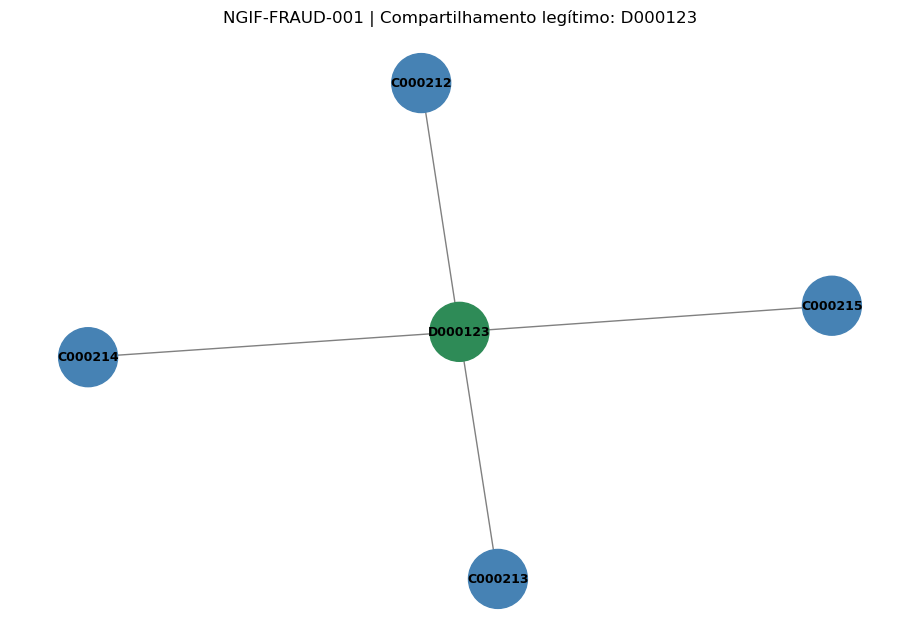

Nós: 5
Relacionamentos: 4


In [40]:
import networkx as nx
import matplotlib.pyplot as plt

# Relações únicas entre clientes e dispositivos
relacoes = (
    sessoes[["cliente_id", "device_id"]]
    .drop_duplicates()
)

# Selecionar um dispositivo compartilhado por 4 contas
dispositivo_exemplo = (
    contas_por_dispositivo[
        contas_por_dispositivo == 4
    ].index[0]
)

# Clientes associados ao dispositivo
subrede = relacoes[
    relacoes["device_id"] == dispositivo_exemplo
]

# Construir grafo bipartido
G = nx.Graph()

for _, linha in subrede.iterrows():
    cliente = linha["cliente_id"]
    dispositivo = linha["device_id"]

    G.add_node(cliente, tipo="cliente")
    G.add_node(dispositivo, tipo="dispositivo")

    G.add_edge(cliente, dispositivo)

# Visualização
plt.figure(figsize=(9, 6))

pos = nx.spring_layout(G, seed=42)

cores = [
    "seagreen" if G.nodes[n]["tipo"] == "dispositivo"
    else "steelblue"
    for n in G.nodes()
]

nx.draw(
    G,
    pos,
    with_labels=True,
    node_color=cores,
    node_size=1800,
    font_size=9,
    font_weight="bold",
    edge_color="gray"
)

plt.title(
    f"NGIF-FRAUD-001 | Compartilhamento legítimo: {dispositivo_exemplo}"
)

plt.show()

print("Nós:", G.number_of_nodes())
print("Relacionamentos:", G.number_of_edges())

# componentes conectados entre clientes e dispositivos

In [41]:
# Relações únicas entre clientes e dispositivos
relacoes = (
    sessoes[["cliente_id", "device_id"]]
    .drop_duplicates()
)

G_identidade = nx.Graph()

# Preservar os tipos das entidades
G_identidade.add_nodes_from(
    clientes["cliente_id"],
    tipo="cliente"
)

G_identidade.add_nodes_from(
    dispositivos["device_id"],
    tipo="dispositivo"
)

# Adicionar relações observadas
G_identidade.add_edges_from(
    relacoes.itertuples(index=False, name=None)
)

componentes = list(nx.connected_components(G_identidade))

tamanhos = pd.Series(
    [len(c) for c in componentes],
    name="tamanho_componente"
)

print("Nós:", G_identidade.number_of_nodes())
print("Relacionamentos:", G_identidade.number_of_edges())
print("Componentes conectados:", len(componentes))

print("\nESTATÍSTICAS DOS COMPONENTES")
display(tamanhos.describe())

print("\nMAIORES COMPONENTES")
display(tamanhos.sort_values(ascending=False).head(10))

Nós: 4709
Relacionamentos: 2665
Componentes conectados: 2044

ESTATÍSTICAS DOS COMPONENTES


count    2044.000000
mean        2.303816
std         1.001792
min         1.000000
25%         2.000000
50%         2.000000
75%         3.000000
max         5.000000
Name: tamanho_componente, dtype: float64


MAIORES COMPONENTES


1190    5
1406    5
556     5
134     5
1550    5
452     5
298     5
1677    5
213     5
1202    5
Name: tamanho_componente, dtype: int64

# buscando os arquivos do neo4j 

In [45]:
import os
print("Seu notebook está aqui:", os.getcwd())
print("Arquivos nesta pasta:", os.listdir("."))
if os.path.exists("../data"):
    print("Arquivos na pasta ../data:", os.listdir("../data"))
else:
    print("A pasta ../data NÃO existe a partir daqui.")

Seu notebook está aqui: c:\Users\SAMSUNG\Desktop\ngif_fraud_001_sprint01\notebooks
Arquivos nesta pasta: ['01_analise_exploratoria.ipynb']
Arquivos na pasta ../data: ['clientes.csv', 'dispositivos.csv', 'domicilios.csv', 'manifest.json', 'ngif_ips_eventos.csv.csv', 'pedidos.csv', 'restaurantes.csv', 'sessoes.csv']


In [46]:
df_ips = pd.read_csv("../data/ngif_ips_eventos.csv")

print("Dimensões:", df_ips.shape)
display(df_ips.head())

Dimensões: (2476, 4)


,ip,sessao_id,dispositivo,instante
0,IP00001,S0007915,D000738,2026-01-01T06:39:00Z
1,IP00001,S0007151,D000671,2026-01-01T18:09:00Z
2,IP00001,S0014499,D001418,2026-01-02T06:14:00Z
3,IP00001,S0007032,D000655,2026-01-02T12:28:00Z
4,IP00001,S0014237,D001390,2026-01-04T06:06:00Z


In [47]:
df_ips["instante"] = pd.to_datetime(
    df_ips["instante"],
    utc=True
)

print(df_ips.info())

print("\nIPs distintos:", df_ips["ip"].nunique())
print("Dispositivos distintos:", df_ips["dispositivo"].nunique())
print("Sessões:", df_ips["sessao_id"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2476 entries, 0 to 2475
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   ip           2476 non-null   object             
 1   sessao_id    2476 non-null   object             
 2   dispositivo  2476 non-null   object             
 3   instante     2476 non-null   datetime64[ns, UTC]
dtypes: datetime64[ns, UTC](1), object(3)
memory usage: 77.5+ KB
None

IPs distintos: 54
Dispositivos distintos: 1031
Sessões: 2476


# verificando a confiabilidade do projeto => validação cruzada

In [48]:
# NGIF-FRAUD-001
# Experimento 01 — Reprodução da análise temporal do Neo4j

import pandas as pd

eventos = (
    df_ips
    .sort_values(["ip", "instante", "sessao_id"])
    .copy()
)

# Evento imediatamente anterior dentro do mesmo IP
eventos["dispositivo_anterior"] = (
    eventos.groupby("ip")["dispositivo"].shift(1)
)

eventos["instante_anterior"] = (
    eventos.groupby("ip")["instante"].shift(1)
)

# Intervalo entre eventos consecutivos
eventos["intervalo_min"] = (
    eventos["instante"] - eventos["instante_anterior"]
).dt.total_seconds() / 60

# Apenas transições entre dispositivos diferentes
transicoes = eventos.loc[
    eventos["dispositivo_anterior"].notna()
    & (
        eventos["dispositivo"]
        != eventos["dispositivo_anterior"]
    )
].copy()

total = len(transicoes)

ate_15 = transicoes["intervalo_min"].between(0, 15).sum()
ate_30 = transicoes["intervalo_min"].between(0, 30).sum()
ate_60 = transicoes["intervalo_min"].between(0, 60).sum()

negativos = (transicoes["intervalo_min"] < 0).sum()

print("Transições:", total)
print("Até 15 minutos:", ate_15)
print("Até 30 minutos:", ate_30)
print("Até 60 minutos:", ate_60)
print("Percentual até 60 min:", round(100 * ate_60 / total, 2), "%")
print("Intervalos negativos:", negativos)

Transições: 2416
Até 15 minutos: 29
Até 30 minutos: 45
Até 60 minutos: 78
Percentual até 60 min: 3.23 %
Intervalos negativos: 0


# Teste de permutação temporal

In [50]:
# NGIF-FRAUD-001
# Experimento 02 — Teste de permutação
# Hipótese: excesso de transições rápidas entre dispositivos

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

N_SIMULACOES = 1000
LIMITE_MINUTOS = 60

# Ordenação cronológica
base = (
    df_ips
    .sort_values(["ip", "instante", "sessao_id"])
    .copy()
)

# Preparar cada IP separadamente
grupos = []

for ip, grupo in base.groupby("ip"):
    dispositivos = grupo["dispositivo"].to_numpy()

    intervalos = (
        grupo["instante"]
        .diff()
        .dt.total_seconds()
        .to_numpy()[1:] / 60
    )

    grupos.append((dispositivos, intervalos))

# Contagem observada
observado = 0

for dispositivos, intervalos in grupos:
    trocou_dispositivo = (
        dispositivos[1:] != dispositivos[:-1]
    )

    observado += np.sum(
        trocou_dispositivo
        & (intervalos >= 0)
        & (intervalos <= LIMITE_MINUTOS)
    )

# Distribuição sob H0
resultados = np.zeros(N_SIMULACOES, dtype=int)

for simulacao in range(N_SIMULACOES):
    total = 0

    for dispositivos, intervalos in grupos:
        embaralhados = rng.permutation(dispositivos)

        trocou_dispositivo = (
            embaralhados[1:] != embaralhados[:-1]
        )

        total += np.sum(
            trocou_dispositivo
            & (intervalos >= 0)
            & (intervalos <= LIMITE_MINUTOS)
        )

    resultados[simulacao] = total

# Teste unilateral para excesso de transições rápidas
p_valor = (
    1 + np.sum(resultados >= observado)
) / (N_SIMULACOES + 1)

print("Transições rápidas observadas:", observado)
print("Média das simulações:", round(resultados.mean(), 2))
print("Desvio-padrão:", round(resultados.std(ddof=1), 2))
print("Mínimo simulado:", resultados.min())
print("Máximo simulado:", resultados.max())
print("Intervalo central 95%:", np.percentile(resultados, [2.5, 97.5]))
print("p-valor unilateral:", round(p_valor, 4))

Transições rápidas observadas: 78
Média das simulações: 77.91
Desvio-padrão: 0.3
Mínimo simulado: 76
Máximo simulado: 78
Intervalo central 95%: [77. 78.]
p-valor unilateral: 0.9091


# visualizando a distribuicao

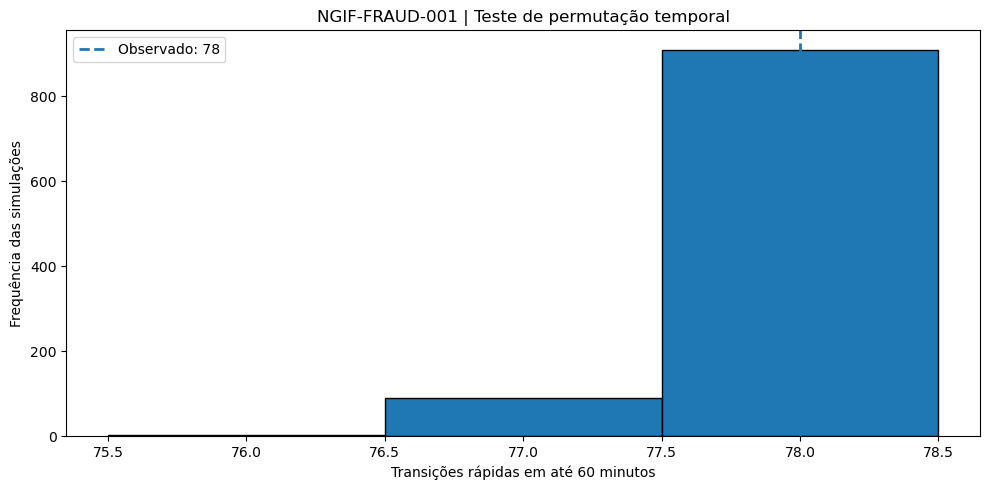

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    resultados,
    bins=np.arange(
        resultados.min() - 0.5,
        resultados.max() + 1.5,
        1
    ),
    edgecolor="black"
)

plt.axvline(
    observado,
    linestyle="--",
    linewidth=2,
    label=f"Observado: {observado}"
)

plt.xlabel("Transições rápidas em até 60 minutos")
plt.ylabel("Frequência das simulações")
plt.title("NGIF-FRAUD-001 | Teste de permutação temporal")
plt.legend()
plt.tight_layout()
plt.show()

# Simulacao Temporal

In [52]:
# NGIF-FRAUD-001
# Experimento 03 — Referência temporal uniforme
# Preserva a quantidade de eventos e a janela temporal de cada IP

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

N_SIMULACOES = 1000
LIMITE_MINUTOS = 60

base = df_ips.sort_values(
    ["ip", "instante", "sessao_id"]
).copy()

grupos = []

for ip, grupo in base.groupby("ip"):

    horarios = grupo["instante"].astype("int64").to_numpy()
    dispositivos = grupo["dispositivo"].to_numpy()

    inicio = horarios.min()
    fim = horarios.max()

    grupos.append((inicio, fim, dispositivos))

resultados_uniformes = np.zeros(N_SIMULACOES, dtype=int)

for simulacao in range(N_SIMULACOES):

    total_rapidas = 0

    for inicio, fim, dispositivos in grupos:

        n = len(dispositivos)

        # Preservar os dois extremos da janela temporal
        if n > 2:
            interiores = rng.uniform(
                inicio,
                fim,
                size=n - 2
            )

            horarios_simulados = np.concatenate(
                ([inicio], interiores, [fim])
            )
        else:
            horarios_simulados = np.array([inicio, fim])

        horarios_simulados.sort()

        # Diferença entre horários consecutivos em minutos
        intervalos = np.diff(horarios_simulados) / 60e9

        # Mantém a sequência observada de dispositivos
        troca = dispositivos[1:] != dispositivos[:-1]

        total_rapidas += np.sum(
            troca & (intervalos <= LIMITE_MINUTOS)
        )

    resultados_uniformes[simulacao] = total_rapidas

observado = 78

p_valor_uniforme = (
    1 + np.sum(resultados_uniformes >= observado)
) / (N_SIMULACOES + 1)

print("Observado:", observado)
print("Média simulada:", round(resultados_uniformes.mean(), 2))
print("Desvio-padrão:", round(resultados_uniformes.std(ddof=1), 2))
print("Intervalo 95%:", np.percentile(resultados_uniformes, [2.5, 97.5]))
print("Mínimo:", resultados_uniformes.min())
print("Máximo:", resultados_uniformes.max())
print("p-valor unilateral:", round(p_valor_uniforme, 4))

Observado: 78
Média simulada: 51.91
Desvio-padrão: 7.03
Intervalo 95%: [39. 66.]
Mínimo: 31
Máximo: 75
p-valor unilateral: 0.001


In [53]:
# Carregar todas as sessões do marketplace sintético
df_sessoes = pd.read_csv("../data/sessoes.csv")

print("Dimensões:", df_sessoes.shape)
print("\nColunas:")
print(df_sessoes.columns.tolist())

display(df_sessoes.head())

Dimensões: (17447, 5)

Colunas:
['sessao_id', 'cliente_id', 'device_id', 'ip_token', 'iniciada_em']


,sessao_id,cliente_id,device_id,ip_token,iniciada_em
0,S0000001,C000001,D000001,IP00101,2026-03-22T20:31:00+00:00
1,S0000002,C000001,D000001,IP00101,2026-01-28T19:12:00+00:00
2,S0000003,C000001,D000001,IP00101,2026-02-17T08:21:00+00:00
3,S0000004,C000001,D000001,IP00101,2026-01-31T14:05:00+00:00
4,S0000005,C000001,D000001,IP00006,2026-01-26T06:54:00+00:00


In [54]:
#  preparando os dados para executar a simulacao
# NGIF-FRAUD-001
# Experimento 04 — Monte Carlo com referência temporal empírica

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

N_SIMULACOES = 1000
LIMITE_MINUTOS = 60

# 1. Preparar os horários reais do marketplace
df_sessoes["iniciada_em"] = pd.to_datetime(
    df_sessoes["iniciada_em"],
    utc=True
)

horarios_reais = (
    df_sessoes["iniciada_em"]
    .astype("int64")
    .to_numpy()
)

# 2. Preparar os grupos de IPs compartilhados
base = df_ips.sort_values(
    ["ip", "instante", "sessao_id"]
).copy()

grupos = []

for ip, grupo in base.groupby("ip"):
    dispositivos = grupo["dispositivo"].to_numpy()
    grupos.append((ip, dispositivos))

# 3. Executar as simulações
resultados_empiricos = np.zeros(
    N_SIMULACOES,
    dtype=int
)

for simulacao in range(N_SIMULACOES):

    total_rapidas = 0

    for ip, dispositivos in grupos:

        n = len(dispositivos)

        # Sortear horários reais da plataforma
        # sem repetir horários dentro do mesmo IP
        horarios_simulados = rng.choice(
            horarios_reais,
            size=n,
            replace=False
        )

        horarios_simulados.sort()

        # Calcular intervalos em minutos
        intervalos = (
            np.diff(horarios_simulados) / 60e9
        )

        # Preservar a sequência observada de dispositivos
        troca = (
            dispositivos[1:]
            != dispositivos[:-1]
        )

        total_rapidas += np.sum(
            troca
            & (intervalos <= LIMITE_MINUTOS)
        )

    resultados_empiricos[simulacao] = total_rapidas

# 4. Comparação com os dados observados
observado = 78

p_valor_empirico = (
    1 + np.sum(resultados_empiricos >= observado)
) / (N_SIMULACOES + 1)

print("Observado:", observado)
print("Média simulada:", round(resultados_empiricos.mean(), 2))
print(
    "Desvio-padrão:",
    round(resultados_empiricos.std(ddof=1), 2)
)
print(
    "Intervalo 95%:",
    np.percentile(resultados_empiricos, [2.5, 97.5])
)
print("Mínimo:", resultados_empiricos.min())
print("Máximo:", resultados_empiricos.max())
print("p-valor unilateral:", round(p_valor_empirico, 4))

Observado: 78
Média simulada: 76.97
Desvio-padrão: 8.53
Intervalo 95%: [60. 94.]
Mínimo: 52
Máximo: 102
p-valor unilateral: 0.4625


In [55]:
# NGIF-FRAUD-001
# Experimento 05 — Análise temporal por IP

import pandas as pd

ranking_ips = (
    transicoes
    .groupby("ip")
    .agg(
        transicoes=("intervalo_min", "size"),
        ate_15_min=(
            "intervalo_min",
            lambda x: x.between(0, 15).sum()
        ),
        ate_30_min=(
            "intervalo_min",
            lambda x: x.between(0, 30).sum()
        ),
        ate_60_min=(
            "intervalo_min",
            lambda x: x.between(0, 60).sum()
        ),
        menor_intervalo_min=("intervalo_min", "min")
    )
    .reset_index()
)

ranking_ips["taxa_60_min"] = (
    ranking_ips["ate_60_min"]
    / ranking_ips["transicoes"]
    * 100
)

ranking_ips = ranking_ips.sort_values(
    ["taxa_60_min", "ate_60_min"],
    ascending=False
)

display(ranking_ips.head(15).round(2))

,ip,transicoes,ate_15_min,ate_30_min,ate_60_min,menor_intervalo_min,taxa_60_min
22,IP00023,51,3,5,5,5.0,9.80
33,IP00034,37,0,0,3,31.0,8.11
23,IP00024,53,1,2,4,0.0,7.55
44,IP00045,40,3,3,3,1.0,7.50
38,IP00039,43,2,3,3,10.0,6.98
10,IP00011,64,1,1,4,9.0,6.25
20,IP00021,51,1,2,3,3.0,5.88
49,IP00050,35,1,2,2,12.0,5.71
12,IP00013,54,3,3,3,2.0,5.56
17,IP00018,57,2,2,3,13.0,5.26


# testar o PI 00023

In [56]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

IP_ALVO = "IP00023"
N_SIMULACOES = 5000

grupo = (
    df_ips[df_ips["ip"] == IP_ALVO]
    .sort_values(["instante", "sessao_id"])
    .copy()
)

dispositivos = grupo["dispositivo"].to_numpy()

intervalos_reais = (
    grupo["instante"]
    .diff()
    .dt.total_seconds()
    .to_numpy()[1:] / 60
)

troca = dispositivos[1:] != dispositivos[:-1]

observado_ip = np.sum(
    troca & (intervalos_reais <= 60)
)

horarios_plataforma = (
    pd.to_datetime(df_sessoes["iniciada_em"], utc=True)
    .astype("int64")
    .to_numpy()
)

resultados_ip = np.zeros(N_SIMULACOES, dtype=int)

for i in range(N_SIMULACOES):

    horarios = rng.choice(
        horarios_plataforma,
        size=len(grupo),
        replace=False
    )

    horarios.sort()

    intervalos = np.diff(horarios) / 60e9

    resultados_ip[i] = np.sum(
        troca & (intervalos <= 60)
    )

p_valor_ip = (
    1 + np.sum(resultados_ip >= observado_ip)
) / (N_SIMULACOES + 1)

print("IP analisado:", IP_ALVO)
print("Sessões:", len(grupo))
print("Transições rápidas observadas:", observado_ip)
print("Média simulada:", round(resultados_ip.mean(), 2))
print("Desvio-padrão:", round(resultados_ip.std(ddof=1), 2))
print("Intervalo 95%:", np.percentile(resultados_ip, [2.5, 97.5]))
print("p-valor unilateral:", round(p_valor_ip, 4))

IP analisado: IP00023
Sessões: 52
Transições rápidas observadas: 5
Média simulada: 1.78
Desvio-padrão: 1.31
Intervalo 95%: [0. 5.]
p-valor unilateral: 0.0294


In [57]:
# NGIF-FRAUD-001
# Sprint 02 — Inspeção do dataset transacional

import pandas as pd

df_pedidos = pd.read_csv("../data/pedidos.csv")

print("Dimensões:", df_pedidos.shape)

print("\nColunas:")
print(df_pedidos.columns.tolist())

print("\nTipos de dados:")
print(df_pedidos.dtypes)

print("\nValores ausentes:")
print(df_pedidos.isna().sum())

print("\nPrimeiros registros:")
display(df_pedidos.head())

Dimensões: (17447, 7)

Colunas:
['pedido_id', 'cliente_id', 'restaurante_id', 'sessao_id', 'criado_em', 'valor_bruto', 'moeda']

Tipos de dados:
pedido_id          object
cliente_id         object
restaurante_id     object
sessao_id          object
criado_em          object
valor_bruto       float64
moeda              object
dtype: object

Valores ausentes:
pedido_id         0
cliente_id        0
restaurante_id    0
sessao_id         0
criado_em         0
valor_bruto       0
moeda             0
dtype: int64

Primeiros registros:


,pedido_id,cliente_id,restaurante_id,sessao_id,criado_em,valor_bruto,moeda
0,P0000001,C000001,R0104,S0000001,2026-03-22T20:31:00+00:00,51.11,BRL
1,P0000002,C000001,R0081,S0000002,2026-01-28T19:12:00+00:00,27.36,BRL
2,P0000003,C000001,R0019,S0000003,2026-02-17T08:21:00+00:00,40.87,BRL
3,P0000004,C000001,R0116,S0000004,2026-01-31T14:05:00+00:00,36.84,BRL
4,P0000005,C000001,R0060,S0000005,2026-01-26T06:54:00+00:00,30.77,BRL


In [58]:
# NGIF-FRAUD-001
# Sprint 02 — Integridade referencial dos pedidos

print("Pedidos distintos:",
      df_pedidos["pedido_id"].nunique())

print("Sessões distintas nos pedidos:",
      df_pedidos["sessao_id"].nunique())

print("Clientes distintos nos pedidos:",
      df_pedidos["cliente_id"].nunique())

print("Restaurantes distintos:",
      df_pedidos["restaurante_id"].nunique())

print("\nPedidos com ID duplicado:",
      df_pedidos["pedido_id"].duplicated().sum())

print("Sessões repetidas nos pedidos:",
      df_pedidos["sessao_id"].duplicated().sum())

print("\nSessões sem correspondência no CSV:")
print(
    (~df_pedidos["sessao_id"]
     .isin(df_sessoes["sessao_id"])).sum()
)

# Verificar se o cliente do pedido é o mesmo da sessão
validacao = df_pedidos.merge(
    df_sessoes[["sessao_id", "cliente_id"]],
    on="sessao_id",
    how="left",
    suffixes=("_pedido", "_sessao"),
    validate="many_to_one"
)

divergencias = (
    validacao["cliente_id_pedido"]
    != validacao["cliente_id_sessao"]
).sum()


Pedidos distintos: 17447
Sessões distintas nos pedidos: 17447
Clientes distintos nos pedidos: 2665
Restaurantes distintos: 120

Pedidos com ID duplicado: 0
Sessões repetidas nos pedidos: 0

Sessões sem correspondência no CSV:
0


In [59]:
print("Divergências entre cliente do pedido e da sessão:")
print(divergencias)

Divergências entre cliente do pedido e da sessão:
0


# preparar conjunto de restaurantes

In [60]:
import pandas as pd

df_pedidos = pd.read_csv("../data/pedidos.csv")

restaurantes_por_conta = (
    df_pedidos
    .groupby("cliente_id")["restaurante_id"]
    .agg(lambda x: set(x))
    .to_dict()
)

print("Contas com pedidos:", len(restaurantes_por_conta))
print("Restaurantes da C002162:",
      len(restaurantes_por_conta["C002162"]))
print("Restaurantes da C002164:",
      len(restaurantes_por_conta["C002164"]))

Contas com pedidos: 2665
Restaurantes da C002162: 22
Restaurantes da C002164: 27


In [61]:
# criar funcao de similariadade

def jaccard_restaurantes(conta_a, conta_b):
    a = restaurantes_por_conta.get(conta_a, set())
    b = restaurantes_por_conta.get(conta_b, set())

    uniao = a | b

    if not uniao:
        return None

    return len(a & b) / len(uniao)


resultado = jaccard_restaurantes("C002162", "C002164")

print(f"Jaccard: {resultado:.4f}")


Jaccard: 0.3243


In [65]:
from pathlib import Path

print("Diretório atual:", Path.cwd())
print("Pasta data esperada:", (Path.cwd() / "../data").resolve())
print("Arquivo existe?", Path("../data/pares_dispositivo.csv").exists())

Diretório atual: c:\Users\SAMSUNG\Desktop\ngif_fraud_001_sprint01\notebooks
Pasta data esperada: C:\Users\SAMSUNG\Desktop\ngif_fraud_001_sprint01\data
Arquivo existe? True


In [66]:
from pathlib import Path

pasta_data = Path("../data")

if pasta_data.exists():
    for arquivo in sorted(pasta_data.glob("*.csv")):
        print(arquivo.name)
else:
    print("A pasta ../data não foi encontrada.")

clientes.csv
dispositivos.csv
domicilios.csv
ngif_ips_eventos.csv
pares_dispositivo.csv
pedidos.csv
restaurantes.csv
sessoes.csv


In [67]:
#preparar os pares de dispositivos

import pandas as pd
import numpy as np

df_pares = pd.read_csv("../data/pares_dispositivo.csv")

print("Pares importados:", len(df_pares))

pares_compartilhados = {
    tuple(sorted((a, b)))
    for a, b in zip(df_pares["conta_1"], df_pares["conta_2"])
}

print("Pares únicos:", len(pares_compartilhados))

Pares importados: 1430
Pares únicos: 1430


# Gerando o gupo B

In [68]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

contas = np.array(sorted(restaurantes_por_conta.keys()))

pares_controle = set()

while len(pares_controle) < len(pares_compartilhados):

    a, b = rng.choice(contas, size=2, replace=False)

    par = tuple(sorted((a, b)))

    if par not in pares_compartilhados:
        pares_controle.add(par)

print("Grupo A:", len(pares_compartilhados))
print("Grupo B:", len(pares_controle))

print(
    "Sobreposição entre grupos:",
    len(pares_compartilhados & pares_controle)
)

Grupo A: 1430
Grupo B: 1430
Sobreposição entre grupos: 0


# Comparando os dois grupos

In [69]:
def calcular_metricas_pares(pares, grupo):

    registros = []

    for a, b in sorted(pares):

        j = jaccard_restaurantes(a, b)

        registros.append({
            "grupo": grupo,
            "conta_1": a,
            "conta_2": b,
            "jaccard": j
        })

    return pd.DataFrame(registros)


df_a = calcular_metricas_pares(
    pares_compartilhados,
    "Compartilham dispositivo"
)

df_b = calcular_metricas_pares(
    pares_controle,
    "Não compartilham dispositivo"
)

df_comparacao = pd.concat(
    [df_a, df_b],
    ignore_index=True
)

resumo = (
    df_comparacao
    .groupby("grupo")["jaccard"]
    .agg(
        pares="count",
        media="mean",
        mediana="median",
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        proporcao_com_restaurantes_em_comum=lambda x: (x > 0).mean()
    )
    .round(4)
)

print(resumo.to_string())

                              pares   media  mediana     p90     p95  proporcao_com_restaurantes_em_comum
grupo                                                                                                    
Compartilham dispositivo       1430  0.0964   0.0714  0.2500  0.3333                               0.5413
Não compartilham dispositivo   1430  0.0298   0.0000  0.1111  0.1667                               0.2133


# Acrescentando o volume de atividade

In [70]:
# Quantidade de pedidos por conta
pedidos_por_conta = (
    df_pedidos.groupby("cliente_id")
    .size()
    .to_dict()
)

# Quantidade de restaurantes distintos por conta
qtd_restaurantes = {
    conta: len(restaurantes)
    for conta, restaurantes in restaurantes_por_conta.items()
}

df_atividade = df_comparacao.copy()

for lado in [1, 2]:
    coluna = f"conta_{lado}"

    df_atividade[f"pedidos_{lado}"] = (
        df_atividade[coluna]
        .map(pedidos_por_conta)
        .fillna(0)
        .astype(int)
    )

    df_atividade[f"restaurantes_{lado}"] = (
        df_atividade[coluna]
        .map(qtd_restaurantes)
        .fillna(0)
        .astype(int)
    )

print(
    df_atividade.groupby("grupo")[
        ["pedidos_1", "pedidos_2",
         "restaurantes_1", "restaurantes_2"]
    ].mean().round(2).to_string()
)

                              pedidos_1  pedidos_2  restaurantes_1  restaurantes_2
grupo                                                                             
Compartilham dispositivo           6.67       6.50            5.28            5.07
Não compartilham dispositivo       6.76       6.49            5.27            5.06


# verificando contas sem historico de pedidos

In [71]:
resumo_atividade = (
    df_atividade.assign(
        ambos_com_pedidos=lambda x:
            (x["pedidos_1"] > 0) &
            (x["pedidos_2"] > 0),

        ambos_com_restaurantes=lambda x:
            (x["restaurantes_1"] > 0) &
            (x["restaurantes_2"] > 0)
    )
    .groupby("grupo")
    .agg(
        pares=("jaccard", "size"),
        jaccard_definido=("jaccard", "count"),
        ambos_com_pedidos=("ambos_com_pedidos", "sum"),
        ambos_com_restaurantes=("ambos_com_restaurantes", "sum")
    )
)

print(resumo_atividade.to_string())

                              pares  jaccard_definido  ambos_com_pedidos  ambos_com_restaurantes
grupo                                                                                           
Compartilham dispositivo       1430              1430               1430                    1430
Não compartilham dispositivo   1430              1430               1430                    1430


# Comparacao por faixa de atividade

In [72]:
df_atividade["total_restaurantes"] = (
    df_atividade["restaurantes_1"] +
    df_atividade["restaurantes_2"]
)

df_atividade["faixa_atividade"] = pd.cut(
    df_atividade["total_restaurantes"],
    bins=[0, 5, 10, 15, 20, float("inf")],
    labels=["1-5", "6-10", "11-15", "16-20", "21+"],
    include_lowest=True
)

comparacao_faixas = (
    df_atividade
    .groupby(
        ["faixa_atividade", "grupo"],
        observed=True
    )
    .agg(
        pares=("jaccard", "count"),
        jaccard_medio=("jaccard", "mean"),
        mediana=("jaccard", "median")
    )
    .round(4)
)

print(comparacao_faixas.to_string())

                                              pares  jaccard_medio  mediana
faixa_atividade grupo                                                      
1-5             Compartilham dispositivo        322         0.0657   0.0000
                Não compartilham dispositivo    327         0.0217   0.0000
6-10            Compartilham dispositivo        540         0.0718   0.0000
                Não compartilham dispositivo    533         0.0251   0.0000
11-15           Compartilham dispositivo        303         0.1152   0.1000
                Não compartilham dispositivo    316         0.0302   0.0000
16-20           Compartilham dispositivo        153         0.1419   0.1333
                Não compartilham dispositivo    155         0.0403   0.0000
21+             Compartilham dispositivo        112         0.1895   0.1703
                Não compartilham dispositivo     99         0.0645   0.0435


# popularidade dos restaurantes

In [73]:
popularidade_restaurantes = (
    df_pedidos
    .groupby("restaurante_id")["cliente_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Total de restaurantes:",
      len(popularidade_restaurantes))

print("\nDistribuição de clientes por restaurante:")
print(popularidade_restaurantes.describe())

print("\n10 restaurantes mais populares:")
print(popularidade_restaurantes.head(10))

Total de restaurantes: 120

Distribuição de clientes por restaurante:
count    120.000000
mean     114.441667
std       80.818689
min        8.000000
25%       54.750000
50%       93.000000
75%      144.500000
max      406.000000
Name: cliente_id, dtype: float64

10 restaurantes mais populares:
restaurante_id
R0060    406
R0022    394
R0020    328
R0112    291
R0087    280
R0114    262
R0027    259
R0074    257
R0006    255
R0116    250
Name: cliente_id, dtype: int64


# Criando pesos dos restaurantes IDF

In [74]:
import numpy as np

total_contas = len(restaurantes_por_conta)

pesos_restaurantes = np.log(
    (total_contas + 1) /
    (popularidade_restaurantes + 1)
) + 1

print("Total de contas:", total_contas)

print("\nRestaurante mais popular:")
print(pesos_restaurantes.loc["R0060"])

print("\nRestaurante menos popular:")
print(pesos_restaurantes.sort_values(ascending=False).head(1))

Total de contas: 2665

Restaurante mais popular:
2.879521315296059

Restaurante menos popular:
restaurante_id
R0110    6.69111
Name: cliente_id, dtype: float64


In [75]:
# criando o jaccard ponderado

def jaccard_ponderado(conta_a, conta_b):

    a = restaurantes_por_conta.get(conta_a, set())
    b = restaurantes_por_conta.get(conta_b, set())

    uniao = a | b
    intersecao = a & b

    if not uniao:
        return None

    peso_intersecao = sum(
        pesos_restaurantes[r] for r in intersecao
    )

    peso_uniao = sum(
        pesos_restaurantes[r] for r in uniao
    )

    return peso_intersecao / peso_uniao


print(
    "Jaccard tradicional:",
    round(jaccard_restaurantes("C002162", "C002164"), 4)
)

print(
    "Jaccard ponderado:",
    round(jaccard_ponderado("C002162", "C002164"), 4)
)

Jaccard tradicional: 0.3243
Jaccard ponderado: 0.3108


# A diferenca permanece nos 2860 pares?

In [76]:
df_ponderado = df_comparacao.copy()

df_ponderado["jaccard_ponderado"] = [
    jaccard_ponderado(a, b)
    for a, b in zip(
        df_ponderado["conta_1"],
        df_ponderado["conta_2"]
    )
]

resumo_ponderado = (
    df_ponderado
    .groupby("grupo")
    .agg(
        pares=("jaccard_ponderado", "count"),
        jaccard_tradicional=("jaccard", "mean"),
        jaccard_ponderado=("jaccard_ponderado", "mean"),
        mediana_ponderada=("jaccard_ponderado", "median"),
        p90_ponderado=(
            "jaccard_ponderado",
            lambda x: x.quantile(0.90)
        ),
        p95_ponderado=(
            "jaccard_ponderado",
            lambda x: x.quantile(0.95)
        )
    )
    .round(4)
)

print(resumo_ponderado.to_string())

                              pares  jaccard_tradicional  jaccard_ponderado  mediana_ponderada  p90_ponderado  p95_ponderado
grupo                                                                                                                       
Compartilham dispositivo       1430               0.0964             0.0894             0.0662         0.2343         0.2996
Não compartilham dispositivo   1430               0.0298             0.0272             0.0000         0.1011         0.1670


# Robustez ao sorteio do controle

In [77]:
import numpy as np

rng = np.random.default_rng(42)

contas = np.array(sorted(restaurantes_por_conta.keys()))
n_pares = len(pares_compartilhados)

medias_controle = []

for simulacao in range(100):

    pares_sorteados = set()

    while len(pares_sorteados) < n_pares:

        a, b = rng.choice(contas, size=2, replace=False)
        par = tuple(sorted((a, b)))

        if par not in pares_compartilhados:
            pares_sorteados.add(par)

    valores = [
        jaccard_ponderado(a, b)
        for a, b in pares_sorteados
    ]

    medias_controle.append(np.mean(valores))

medias_controle = np.array(medias_controle)

media_grupo_a = df_ponderado.loc[
    df_ponderado["grupo"] == "Compartilham dispositivo",
    "jaccard_ponderado"
].mean()

print("Média Grupo A:", round(media_grupo_a, 4))
print("Média dos controles:", round(medias_controle.mean(), 4))
print("Desvio-padrão:", round(medias_controle.std(), 4))
print("Mínimo:", round(medias_controle.min(), 4))
print("Máximo:", round(medias_controle.max(), 4))
print("Percentil 2,5:", round(np.percentile(medias_controle, 2.5), 4))
print("Percentil 97,5:", round(np.percentile(medias_controle, 97.5), 4))

Média Grupo A: 0.0894
Média dos controles: 0.0274
Desvio-padrão: 0.0017
Mínimo: 0.0227
Máximo: 0.0312
Percentil 2,5: 0.024
Percentil 97,5: 0.0303


In [ ]:
# Alexandre Lotti
# <!LOTTI>